# 05 · La decisión: qué comprar con Q300
**Responsable:** Nacho

**Decisión:** un jugador con **Q300** en la oferta de invierno de Steam: ¿qué juegos compra y cuáles evita?

**Entradas:**
- `outputs/pred_calidad.csv` y `outputs/umbral.json` (notebook 02): probabilidad de que cada juego sea bien recibido y el umbral elegido por costos.
- `src/recomendador.py` (notebook 03): qué tanto se parece cada juego a los favoritos del jugador.
- `juegos.parquet`: precios y reseñas reales.

**El modelo propone, las reseñas reales confirman.** El modelo del 02 estima la calidad *sin leer reseñas*, así que sirve para juegos nuevos o con pocas reseñas. Pero todos los juegos de este dataset ya tienen reseñas (al menos `C.MIN_RESENAS`), y cuando el dato real existe, manda el dato real: se usa para confirmar lo que dice el modelo (sección 5.1).

**Supuestos (en `src/config.py`):**
- **Plan B:** no hay datos de la oferta de diciembre, así que el precio en oferta es el precio de lista con un descuento típico (`C.DESCUENTO_TIPICO = 50 %`). En la sección 6 se ve qué pasa con otros descuentos.
- Tasa fija de `C.TASA_GTQ_USD` quetzales por dólar.
- Como máximo `C.MAX_JUEGOS_LISTA = 5` juegos: nadie juega 40 juegos a la vez, aunque sean baratos.

La lógica está en `src/decision.py`, para que la misma función sirva en otros lugares.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config as C
from src.decision import tabla_candidatos, filtrar, elegir_optimo, elegir_codicioso, evitar, cargar_umbral

pd.set_option("display.max_colwidth", 45)
COLS = ["nombre", "precio_oferta_gtq", "p_bien_recibido", "pct_positivo", "similitud", "puntaje"]

## 1. El jugador de ejemplo
Le gustaron **DOOM** y **Hades** (`C.FAVORITOS_EJEMPLO`). Con eso se calcula, para cada juego, qué tanto se parece a sus gustos.

In [2]:
cand = tabla_candidatos(C.FAVORITOS_EJEMPLO)
umbral = cargar_umbral()
print(f"umbral de calidad (notebook 02): {umbral}")
cand.sort_values("similitud", ascending=False)[COLS + ["pasa_umbral"]].head(10).round(3)

umbral de calidad (notebook 02): 0.66


,nombre,precio_oferta_gtq,p_bien_recibido,pct_positivo,similitud,puntaje,pasa_umbral
44472,PERISH,76.84,0.717,0.723,0.712,0.511,True
29025,DOOM Eternal,153.84,0.889,0.912,0.700,0.622,True
3158,DOOM Eternal: The Ancient Gods - Part Two,76.89,0.678,0.608,0.679,0.460,True
30160,Paranautical Activity: Deluxe Atonement E...,38.19,0.515,0.683,0.671,0.346,False
22446,SWORN,96.18,0.557,0.829,0.669,0.372,False
7679,Hades II,115.46,0.768,0.949,0.669,0.514,True
19573,Wraithbinder,57.71,0.528,1.000,0.655,0.346,False
38269,Dreamscaper,96.06,0.398,0.882,0.655,0.261,False
20447,Rogue Girl,8.78,0.591,0.692,0.655,0.387,False
2587,Dead Purge: Outbreak,57.56,0.211,0.453,0.642,0.135,False


## 2. El puntaje: calidad × parecido
Para cada juego:

**puntaje = p_bien_recibido × similitud**

- Un juego excelente que no tiene nada que ver con los gustos del jugador tiene puntaje bajo.
- Un juego muy parecido pero que probablemente sea malo, también.
- Solo los que son **buenos y parecidos a la vez** tienen puntaje alto.

## 3. ¿Quiénes compiten? (el embudo)
1. Se descartan los **gratis**: no gastan presupuesto, se pueden bajar aparte.
2. Se descartan los que **no pasan el umbral de calidad** del notebook 02 (p < 0.66).
3. Se descartan los que el modelo cree buenos pero sus **reseñas reales dicen que no** (80 % positivas o menos).
4. De los que quedan, solo los **`C.N_CANDIDATOS` más parecidos** a los favoritos.

In [3]:
de_pago = cand[~cand["es_gratis"]]
pasan = de_pago[de_pago["pasa_umbral"]]
confirmados = pasan[pasan["bien_recibido"]]
finales = filtrar(cand)
embudo = pd.Series({
    "todos los juegos": len(cand),
    "de pago": len(de_pago),
    "pasan el umbral de calidad": len(pasan),
    "y sus reseñas reales lo confirman": len(confirmados),
    f"los {C.N_CANDIDATOS} más parecidos": len(finales),
}, name="juegos")
embudo

todos los juegos                     44566
de pago                              38601
pasan el umbral de calidad           15046
y sus reseñas reales lo confirman    12171
los 300 más parecidos                  300
Name: juegos, dtype: int64

## 4. Elegir la mejor combinación dentro del presupuesto
Es el **problema de la mochila**: cada juego tiene un costo (su precio) y un valor (su puntaje), y hay que elegir la combinación con **más valor total** sin pasarse de Q300 ni de 5 juegos.

Se resuelve exacto con programación dinámica (`elegir_optimo`). Se compara con la forma intuitiva, el método **codicioso** (`elegir_codicioso`): ordenar por puntaje y agregar mientras quepa.

In [4]:
lista = elegir_optimo(finales, C.PRESUPUESTO_GTQ)
print(f"Con Q{C.PRESUPUESTO_GTQ}, compra estos {len(lista)}:")
print(f"total Q{lista['precio_oferta_gtq'].sum():.2f} · sobran Q{C.PRESUPUESTO_GTQ - lista['precio_oferta_gtq'].sum():.2f}")
lista[COLS].round(3)

Con Q300, compra estos 5:
total Q284.30 · sobran Q15.70


,nombre,precio_oferta_gtq,p_bien_recibido,pct_positivo,similitud,puntaje
0,DOOM Eternal,153.84,0.889,0.912,0.700,0.622
1,Far Cry®,38.38,0.878,0.819,0.642,0.563
2,Risk of Rain (2013),38.30,0.949,0.933,0.585,0.555
3,DOOM + DOOM II,38.42,0.940,0.965,0.583,0.548
4,Quake,15.36,0.921,0.967,0.583,0.537


In [5]:
comparacion = []
for presupuesto in [50, 100, 200, 300, 500]:
    o = elegir_optimo(finales, presupuesto)
    g = elegir_codicioso(finales, presupuesto)
    comparacion.append({"presupuesto": presupuesto,
                        "puntaje óptimo": o["puntaje"].sum(), "puntaje codicioso": g["puntaje"].sum(),
                        "gasto óptimo": o["precio_oferta_gtq"].sum(), "gasto codicioso": g["precio_oferta_gtq"].sum()})
pd.DataFrame(comparacion).set_index("presupuesto").round(3)

,puntaje óptimo,puntaje codicioso,gasto óptimo,gasto codicioso
presupuesto,,,,
50,2.404,1.527,44.46,48.31
100,2.559,2.146,86.58,99.70
200,2.750,1.675,191.82,199.88
300,2.826,2.826,284.30,284.30
500,2.833,2.833,307.36,307.36


## 5. Cuáles evitar
Los más **tentadores**: muy parecidos a lo que le gusta al jugador, pero el modelo predice que **no** serán bien recibidos **y** sus reseñas reales lo confirman.

In [6]:
evitar(cand)[COLS + ["total_resenas"]].round(3)

,nombre,precio_oferta_gtq,p_bien_recibido,pct_positivo,similitud,puntaje,total_resenas
0,Paranautical Activity: Deluxe Atonement E...,38.19,0.515,0.683,0.671,0.346,1408
1,Rogue Girl,8.78,0.591,0.692,0.655,0.387,39
2,Dead Purge: Outbreak,57.56,0.211,0.453,0.642,0.135,86
3,I Shall Remain,38.46,0.212,0.679,0.641,0.136,159
4,Perseus: Titan Slayer,30.42,0.354,0.652,0.627,0.222,339


### 5.1 ¿Por qué confirmar con las reseñas reales?
Si la lista de evitar usara **solo el modelo**, saldrían estos. Varios en realidad están bien reseñados: el umbral de 0.66 es exigente a propósito (prefiere perderse un juego bueno antes que comprar uno malo) y por eso deja fuera a muchos juegos buenos. Eso está bien para *no comprar*, pero no para decirle a alguien *"evita este juego"*.

In [7]:
no_pasan = de_pago[~de_pago["pasa_umbral"]]
print(f"de los {len(no_pasan):,} juegos de pago que NO pasan el umbral, "
      f"{no_pasan['bien_recibido'].mean():.0%} en realidad están bien reseñados")
solo_modelo = no_pasan.nlargest(5, "similitud")
solo_modelo[["nombre", "p_bien_recibido", "pct_positivo", "total_resenas", "bien_recibido"]].round(3)

de los 23,555 juegos de pago que NO pasan el umbral, 37% en realidad están bien reseñados


,nombre,p_bien_recibido,pct_positivo,total_resenas,bien_recibido
30160,Paranautical Activity: Deluxe Atonement E...,0.515,0.683,1408,False
22446,SWORN,0.557,0.829,2461,True
19573,Wraithbinder,0.528,1.000,20,True
20447,Rogue Girl,0.591,0.692,39,False
38269,Dreamscaper,0.398,0.882,3028,True


## 6. ¿Qué tan estable es la decisión?
### 6.1 Otros presupuestos

In [8]:
listas = {p: elegir_optimo(finales, p) for p in [150, 300, 500]}
filas = []
for p, l in listas.items():
    for _, j in l.iterrows():
        filas.append({"presupuesto": f"Q{p}", "juego": j["nombre"], "precio": j["precio_oferta_gtq"]})
tabla = pd.DataFrame(filas).pivot_table(index="juego", columns="presupuesto", values="precio", aggfunc="first")
tabla[[f"Q{p}" for p in [150, 300, 500]]].fillna("–")

presupuesto,Q150,Q300,Q500
juego,,,
DOOM + DOOM II,38.42,38.42,38.42
DOOM Eternal,–,153.84,153.84
Far Cry®,38.38,38.38,38.38
Quake,15.36,15.36,–
Quake II,–,–,38.42
Risk of Rain (2013),38.3,38.3,38.3
Serious Sam Classics: Revolution,7.66,–,–


### 6.2 Otros descuentos (plan B)
No sabemos cuál será el descuento real de diciembre. ¿Cambia la lista si es de 25 % o de 75 %?

In [9]:
resumen = []
for d in [0.25, 0.50, 0.75]:
    l = elegir_optimo(filtrar(tabla_candidatos(C.FAVORITOS_EJEMPLO, descuento=d)), C.PRESUPUESTO_GTQ)
    resumen.append({"descuento": f"{d:.0%}", "juegos": len(l), "gasto": l["precio_oferta_gtq"].sum(),
                    "puntaje": l["puntaje"].sum(), "lista": ", ".join(l["nombre"])})
pd.DataFrame(resumen).set_index("descuento").round(2)

,juegos,gasto,puntaje,lista
descuento,,,,
25%,5,287.78,2.75,"Far Cry®, Risk of Rain (2013), DOOM + DOO..."
50%,5,284.30,2.83,"DOOM Eternal, Far Cry®, Risk of Rain (201..."
75%,5,153.68,2.83,"DOOM Eternal, Far Cry®, Risk of Rain (201..."


### 6.3 Otro jugador
La lista depende de los gustos. Un jugador al que le gustaron **Stardew Valley** y **Terraria**:

In [10]:
otro = filtrar(tabla_candidatos([413150, 105600]))
elegir_optimo(otro, C.PRESUPUESTO_GTQ)[COLS].round(3)

,nombre,precio_oferta_gtq,p_bien_recibido,pct_positivo,similitud,puntaje
0,Necesse,57.68,0.801,0.937,0.775,0.621
1,Don't Starve Together,57.64,0.916,0.953,0.652,0.597
2,Forager,76.89,0.734,0.899,0.799,0.587
3,Crashlands,57.60,0.862,0.896,0.678,0.585
4,Risk of Rain (2013),38.30,0.949,0.933,0.594,0.564


## 7. Resumen visual

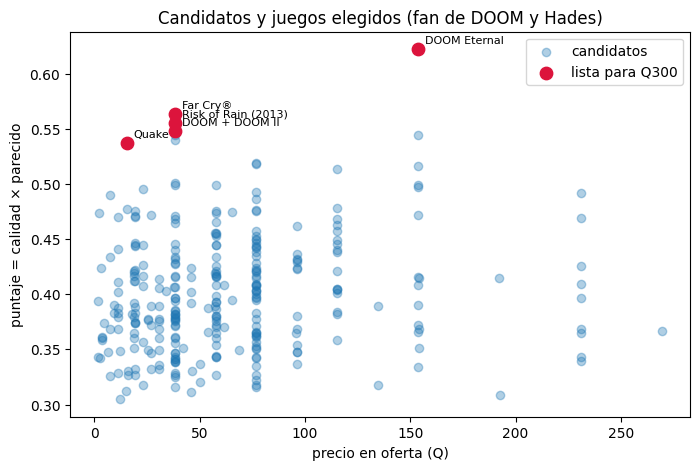

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(finales["precio_oferta_gtq"], finales["puntaje"], alpha=0.35, label="candidatos")
ax.scatter(lista["precio_oferta_gtq"], lista["puntaje"], color="crimson", s=80, label=f"lista para Q{C.PRESUPUESTO_GTQ}")
for _, j in lista.iterrows():
    ax.annotate(j["nombre"][:22], (j["precio_oferta_gtq"], j["puntaje"]), xytext=(5, 4),
                textcoords="offset points", fontsize=8)
ax.set(xlabel="precio en oferta (Q)", ylabel="puntaje = calidad × parecido",
       title="Candidatos y juegos elegidos (fan de DOOM y Hades)")
ax.legend()
fig.savefig(C.FIGURAS / "05_decision.png", dpi=120, bbox_inches="tight")

In [12]:
lista[["appid"] + COLS].to_csv(C.OUTPUTS / "lista_compra_q300.csv", index=False)
evitar(cand)[["appid"] + COLS].to_csv(C.OUTPUTS / "lista_evitar.csv", index=False)
print("guardado: outputs/lista_compra_q300.csv y outputs/lista_evitar.csv")

guardado: outputs/lista_compra_q300.csv y outputs/lista_evitar.csv


## Conclusiones

**La decisión, para un fan de DOOM y Hades con Q300 (descuento supuesto de 50 %):**

| Compra | Precio en oferta | Prob. del modelo | % positivo real | Parecido |
|---|---|---|---|---|
| DOOM Eternal | Q153.84 | 0.89 | 91 % | 0.70 |
| Far Cry | Q38.38 | 0.88 | 82 % | 0.64 |
| Risk of Rain (2013) | Q38.30 | 0.95 | 93 % | 0.59 |
| DOOM + DOOM II | Q38.42 | 0.94 | 97 % | 0.58 |
| Quake | Q15.36 | 0.92 | 97 % | 0.58 |
| **Total** | **Q284.30** (sobran Q15.70) | | | |

**Evita:** Paranautical Activity, Rogue Girl, Dead Purge: Outbreak, I Shall Remain y Perseus: Titan Slayer. Son de los juegos *más parecidos* a sus gustos (justo los que compraría por impulso), el modelo predice que no serán bien recibidos y sus reseñas reales lo confirman (entre 45 % y 69 % positivas).

**Lo que muestra el análisis:**
1. **El modelo propone, las reseñas reales confirman.** El umbral de 0.66 es exigente a propósito: de los juegos de pago que no lo pasan, el 37 % en realidad está bien reseñado. Si la lista de evitar usara solo el modelo, incluiría a Dreamscaper (88 % positivo) y a SWORN (83 %), que son buenos. Por eso un juego entra a "evitar" solo si las reseñas reales también dicen que es malo. Lo mismo al revés: *PERISH* es el juego más parecido a DOOM + Hades y pasa el umbral del modelo (0.72), pero sus reseñas reales (72 %) lo dejan fuera de la lista.
2. **¿Para qué el modelo, si Steam ya muestra las reseñas?** Porque estima la calidad *sin leer reseñas*: sirve para juegos nuevos o con pocas reseñas, que son justo los que un jugador no puede juzgar. En el examen del notebook 02 acierta con AUC 0.81. Cuando el juego ya tiene muchas reseñas, manda el dato real.
3. **Optimizar vale la pena con presupuestos chicos.** Con Q50, Q100 y Q200 la mochila obtiene bastante más puntaje que el método codicioso (con Q200: 2.75 contra 1.68). El codicioso agarra DOOM Eternal primero porque tiene el mayor puntaje, y con lo que sobra solo le alcanza para 2 juegos más. La mochila prefiere 5 juegos buenos más baratos. Con Q300 y Q500 los dos métodos dan lo mismo, porque el límite que pesa es el de 5 juegos.
4. **La lista es estable.** Al pasar de Q150 a Q500, el núcleo (Far Cry, Risk of Rain, DOOM + DOOM II) se mantiene. Con más dinero entra DOOM Eternal. Con un descuento de 75 %, alcanza para la misma lista gastando solo Q154.
5. **Es personal.** Para un fan de Stardew Valley y Terraria, la lista cambia casi por completo: Necesse, Don't Starve Together, Forager, Crashlands y Risk of Rain.

**Limitaciones:**
- **Plan B:** el precio en oferta supone el mismo 50 % de descuento para todos los juegos. En la oferta real cada juego tiene su descuento, y algunos no tienen ninguno.
- **Los favoritos se promedian:** con gustos muy distintos, el perfil queda "en medio" (ver notebook 03).
- **El puntaje multiplica calidad y parecido con el mismo peso.** Es una elección nuestra; podría darse más peso a uno de los dos.
- **No sabemos si el precio bajará más después** (el dataset no trae historial de precios). La decisión es "qué comprar con lo que hay hoy".
- Los juegos de una misma franquicia (DOOM, DOOM Eternal, DOOM + DOOM II) se cuentan como distintos. Un jugador que ya tiene DOOM probablemente tenga DOOM + DOOM II. Una mejora sería excluir la franquicia de los favoritos.